In [4]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [5]:
import pandas as pd
import numpy as np
import tensorflow as tf
import os
import cv2
import random
import gc
import seaborn as sns
import matplotlib.pyplot as plt
from keras.preprocessing.image import load_img
import keras,os
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense, Activation,GlobalMaxPooling2D
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from keras.applications.xception import Xception
from keras.applications.vgg19 import VGG19
from keras.models import Model
from keras import optimizers , layers, applications
from keras import regularizers
from tqdm import tqdm

Adam=tf.keras.optimizers.Adam()

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve

In [6]:
train_list_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/train/Autistic')
train_list_non_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/train/Non_Autistic')
test_list_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/test/Autistic')
test_list_non_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/test/Non_Autistic')
valid_list_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/valid/Autistic')
valid_list_non_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/valid/Non_Autistic')

In [7]:
x_train = np.zeros((len(train_list_autistic)*2, 224,224,3), dtype=np.uint8)
x_val = np.zeros((len(valid_list_autistic)*2, 224,224,3), dtype=np.uint8)
x_test = np.zeros((len(test_list_autistic)*2, 224,224,3), dtype=np.uint8)
y_train = np.zeros((len(train_list_autistic)*2), dtype=np.uint8)
y_val = np.zeros((len(valid_list_autistic)*2), dtype=np.uint8)
y_test = np.zeros((len(test_list_autistic)*2), dtype=np.uint8)

In [8]:
x_train.shape

(2540, 224, 224, 3)

In [9]:
int(len(train_list_non_autistic))

1270

In [10]:
for i in tqdm(range(len(train_list_non_autistic))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/train/Non_Autistic/'+str(train_list_non_autistic[i]), target_size=(224,224), color_mode='rgb')
    x_train[i]=img
for i in tqdm(range(len(train_list_autistic),(2*len(train_list_autistic)))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/train/Autistic/'+str(train_list_autistic[i-int(len(train_list_non_autistic))]), target_size=(224,224), color_mode='rgb')
    x_train[i]=img
    y_train[i]=1

100%|██████████| 1270/1270 [12:48<00:00,  1.65it/s]


In [11]:
for i in tqdm(range(len(valid_list_non_autistic))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/valid/Non_Autistic/'+str(valid_list_non_autistic[i]), target_size=(224,224), color_mode='rgb')
    x_val[i]=img
for i in tqdm(range(len(valid_list_autistic),(2*len(valid_list_autistic)))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/valid/Autistic/'+str(valid_list_autistic[i-int(len(valid_list_non_autistic))]), target_size=(224,224), color_mode='rgb')
    x_val[i]=img
    y_val[i]=1

100%|██████████| 50/50 [00:29<00:00,  1.67it/s]


In [12]:
for i in tqdm(range(len(test_list_non_autistic))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/test/Non_Autistic/'+str(test_list_non_autistic[i]), target_size=(224,224), color_mode='rgb')
    x_test[i]=img
for i in tqdm(range(len(test_list_autistic),(2*len(test_list_autistic)))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/test/Autistic/'+str(test_list_autistic[i-int(len(test_list_non_autistic))]), target_size=(224,224), color_mode='rgb')
    x_test[i]=img
    y_test[i]=1

100%|██████████| 100/100 [01:00<00:00,  1.66it/s]


In [13]:
x_train = x_train/255.0
x_val = x_val/255.0
x_test = x_test/255.0

In [14]:
x_val.shape

(100, 224, 224, 3)

**VGG-19 MODEL**

In [16]:
image_size = 224
input_shape = (image_size, image_size,3)

#Hyperparameters
epochs = 30
batch_size = 32

pre_trained_model = VGG19(input_shape=input_shape, include_top=False, weights="imagenet")
    
for layer in pre_trained_model.layers:
    layer.trainable = False

# Flatten the output layer to 1 dimension
vggmodel = keras.models.Sequential()
vggmodel.add(pre_trained_model)
vggmodel.add(layers.Flatten())
# Add a fully connected layer with 128 hidden units and ReLU activation
vggmodel.add(layers.Dense(1024, activation='relu'))
# Add a dropout rate of 0.5
vggmodel.add(layers.Dropout(0.3))
# Add a fully connected layer with 64 hidden units and ReLU activation
vggmodel.add(layers.Dense(512, activation='relu'))
#x.add(layers.Dropout(0.3))
# Add a final sigmoid layer for classification
vggmodel.add(layers.Dense(1, activation='sigmoid',kernel_regularizer=regularizers.l2(0.0001)))

vggmodel.compile(loss='binary_crossentropy',
             optimizer =  tf.keras.optimizers.Adam(),
              metrics=['accuracy'])

vggmodel.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg19 (Functional)          (None, 7, 7, 512)         20024384  
                                                                 
 flatten_1 (Flatten)         (None, 25088)             0         
                                                                 
 dense_3 (Dense)             (None, 1024)              25691136  
                                                                 
 dropout_1 (Dropout)         (None, 1024)              0         
                                                                 
 dense_4 (Dense)             (None, 512)               524800    
                                                                 
 dense_5 (Dense)             (None, 1)                 513       
                                                                 
Total params: 46,240,833
Trainable params: 26,216,449


In [17]:
#Fit Model
history2 = vggmodel.fit(x = x_train,y = y_train, validation_data = (x_val,y_val), epochs = 28, batch_size = 32)

Epoch 1/28
80/80 [==============================] - 31s 211ms/step - loss: 1.0431 - accuracy: 0.6705 - val_loss: 0.4997 - val_accuracy: 0.7700
Epoch 2/28
80/80 [==============================] - 14s 180ms/step - loss: 0.4371 - accuracy: 0.8000 - val_loss: 0.4365 - val_accuracy: 0.8100
Epoch 3/28
80/80 [==============================] - 15s 183ms/step - loss: 0.3922 - accuracy: 0.8252 - val_loss: 0.4472 - val_accuracy: 0.7900
Epoch 4/28
80/80 [==============================] - 15s 186ms/step - loss: 0.3508 - accuracy: 0.8445 - val_loss: 0.4484 - val_accuracy: 0.7800
Epoch 5/28
80/80 [==============================] - 15s 189ms/step - loss: 0.3526 - accuracy: 0.8386 - val_loss: 0.7612 - val_accuracy: 0.6400
Epoch 6/28
80/80 [==============================] - 15s 191ms/step - loss: 0.3303 - accuracy: 0.8547 - val_loss: 0.4366 - val_accuracy: 0.8200
Epoch 7/28
80/80 [==============================] - 16s 196ms/step - loss: 0.2837 - accuracy: 0.8787 - val_loss: 0.5520 - val_accuracy: 0.7500

In [18]:
y_pred1 = vggmodel.predict(x_test)

In [19]:
y_pred1 = y_pred1.round()

In [21]:
print(accuracy_score(y_pred1,y_test)*100)

84.5


In [22]:
print(classification_report(y_pred1,y_test))

              precision    recall  f1-score   support

         0.0       0.88      0.82      0.85       107
         1.0       0.81      0.87      0.84        93

    accuracy                           0.84       200
   macro avg       0.84      0.85      0.84       200
weighted avg       0.85      0.84      0.85       200



In [23]:
cn_matrix= confusion_matrix(y_pred1,y_test)
cn_matrix

array([[88, 19],
       [12, 81]])

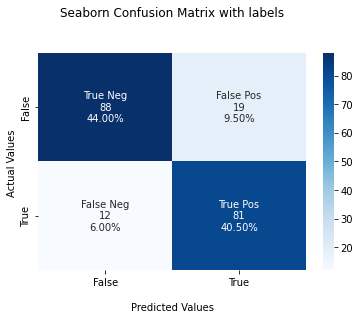

In [24]:
group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cn_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cn_matrix.flatten()/np.sum(cn_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cn_matrix, annot=labels, fmt='', cmap='Blues')

ax.set_title('Seaborn Confusion Matrix with labels\n\n');
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

In [25]:
print("Average training loss: ", np.average(history2.history['loss']))
print("Average training accuracy: ", np.average(history2.history['accuracy']))
print("Average validation loss: ", np.average(history2.history['val_loss']))
print("Average validation accuracy: ", np.average(history2.history['val_accuracy']))

Average training loss:  0.26739192727421013
Average training accuracy:  0.8788807626281466
Average validation loss:  0.5843075205172811
Average validation accuracy:  0.7674999982118607


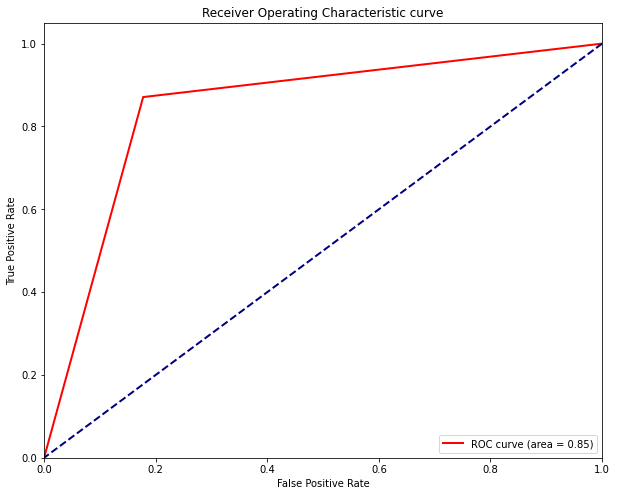

In [26]:
fpr, tpr, _ = roc_curve(y_pred1,y_test)
roc_auc= auc(fpr, tpr)
plt.figure(figsize = (10,8))
plt.plot(fpr, tpr, color = 'red', lw = 2, label = 'ROC curve (area = %0.2f)' % roc_auc)
plt.plot([1,0], [1,0], color = 'navy', lw = 2, linestyle = '--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title("Receiver Operating Characteristic curve")
plt.legend(loc = 'lower right')

In [28]:
vggmodel.save('vgg19.h5')